# Phase 10 - Decision Engine Pre-RL (GBPUSD)

Esta fase construye una capa de decisión sobre las señales de `phase9.3` y evalúa en walk-forward con costos.

In [1]:
from pathlib import Path
import subprocess

ROOT = Path('.')
SCRIPT = ROOT / 'phases/phase10_decision_engine/run_phase10_decision_engine_pre_rl.py'

res = subprocess.run(['python', str(SCRIPT)], cwd=ROOT, check=True, capture_output=True, text=True)
print(res.stdout)
if res.stderr:
    print(res.stderr)


Saved summary: ./phases/phase10_decision_engine/output_phase10_decision_pre_rl_GBPUSD/GBPUSD_phase10_summary.json
Walk-forward mean metrics:
{'fold': 3.0, 'train_rows': 15573.0, 'test_rows': 2396.0, 'conf_thr': 0.5, 'inf_min': 0.4, 'calib_score': 1.8918391625158093, 'acc_action_3': 0.251085141903172, 'f1_macro_action_3': 0.2290765268767138, 'avg_net_return': 0.00010412199138620875, 'cum_net_return': 0.24947629136135613, 'std_net_return': 0.002662866991235518, 'sharpe_ann': 2.491926805568011, 'trade_rate': 0.1933221999555826, 'win_rate_trades': 0.5630139199181614}



In [2]:
import json
import pandas as pd
from IPython.display import display

OUT = ROOT / 'phases/phase10_decision_engine/output_phase10_decision_pre_rl_GBPUSD'
summary = json.loads((OUT / 'GBPUSD_phase10_summary.json').read_text())
metrics = pd.read_csv(OUT / 'GBPUSD_phase10_walkforward_metrics.csv')
preds = pd.read_csv(OUT / 'GBPUSD_phase10_fold_predictions.csv')

print('Summary keys:', summary.keys())
print('Dataset:', summary['dataset'])
print('Walk-forward mean metrics:')
display(pd.Series(summary['walkforward']['mean_metrics']).to_frame('mean'))
print('Fold metrics:')
display(metrics)
print('Pred action distribution:')
display(preds['pred_action'].value_counts().sort_index())


Summary keys: dict_keys(['symbol', 'model_tag', 'description', 'config', 'phase9_best_threshold', 'dataset', 'walkforward', 'outputs'])
Dataset: {'n_inference_rows': 30511, 'n_decision_rows': 23967, 'action_distribution': {'-1': 10186, '0': 3768, '1': 10013}, 'date_min': '2000-05-31 10:00:00', 'date_max': '2025-10-29 19:00:00'}
Walk-forward mean metrics:


,mean
fold,3.000000
train_rows,15573.000000
test_rows,2396.000000
conf_thr,0.500000
inf_min,0.400000
calib_score,1.891839
acc_action_3,0.251085
f1_macro_action_3,0.229077
avg_net_return,0.000104
cum_net_return,0.249476


Fold metrics:


,fold,train_rows,test_rows,timestamp_test_start,timestamp_test_end,conf_thr,inf_min,calib_score,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,sharpe_ann,trade_rate,win_rate_trades
0,1,10781,2396,2010-01-26 01:00:00,2011-10-21 04:00:00,0.65,0.45,2.428118,0.140651,0.089103,-0.000001,-0.003517,0.000618,-0.184799,0.011269,0.592593
1,2,13177,2396,2011-10-21 05:00:00,2016-01-29 05:00:00,0.40,0.50,1.976679,0.268364,0.237927,0.000065,0.156699,0.002271,2.239482,0.167780,0.544776
2,3,15573,2396,2016-01-29 06:00:00,2018-02-02 02:00:00,0.40,0.45,1.807804,0.345159,0.340236,0.000144,0.345938,0.004094,2.742418,0.360184,0.539977
3,4,17969,2396,2018-02-02 03:00:00,2020-09-21 00:00:00,0.55,0.30,2.025182,0.236644,0.216058,0.000137,0.328321,0.002813,3.788416,0.159432,0.578534
4,5,20365,2396,2020-09-21 01:00:00,2023-05-12 05:00:00,0.50,0.30,1.221413,0.264608,0.262060,0.000175,0.419939,0.003518,3.874117,0.267947,0.559190


Pred action distribution:


pred_action
-1    1322
 0    9664
 1     994
Name: count, dtype: int64

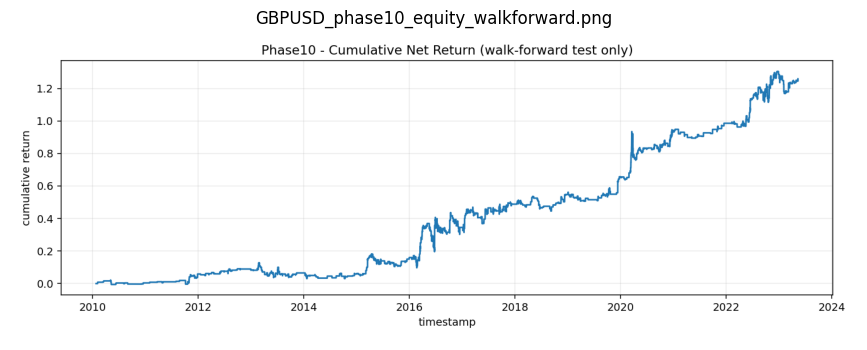

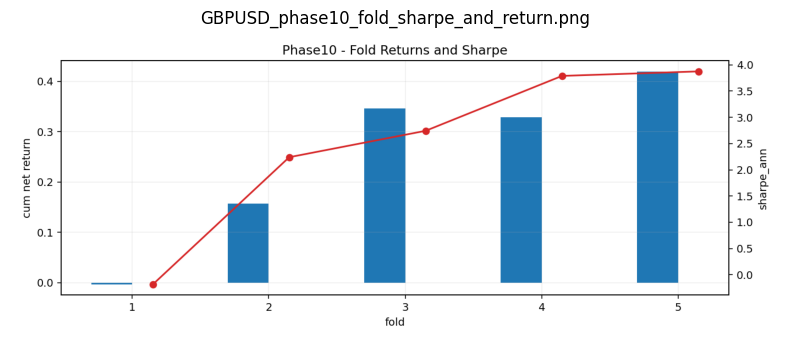

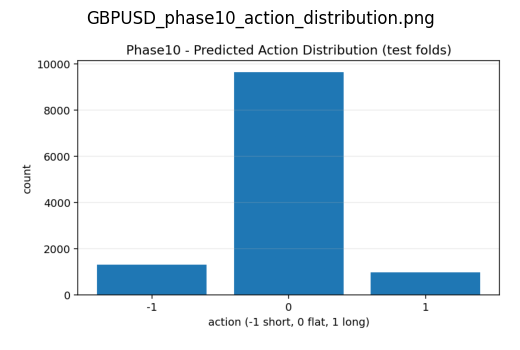

In [3]:
import matplotlib.pyplot as plt

img_paths = [
    OUT / 'GBPUSD_phase10_equity_walkforward.png',
    OUT / 'GBPUSD_phase10_fold_sharpe_and_return.png',
    OUT / 'GBPUSD_phase10_action_distribution.png',
]

for p in img_paths:
    img = plt.imread(p)
    plt.figure(figsize=(12, 4))
    plt.imshow(img)
    plt.title(p.name)
    plt.axis('off')
    plt.show()
